# Prioritizing Workforce Retraining for Occupations Exposed to Automation


**Master of Science in Data Science project**  
**Student:** Sai Krishna Reddy M.


## Data provenance


The analytical file merges the ratings for occupations on the O*NET database with the U.S. Bureau of Labor Statistics 2025-2035 National Employment Matrix job and occupational level and ratings at the 6-digit SOC level. O*NET uses its established data-collection program to rate occupations, while BLS provides national estimates for employment, wages, projected growth, and annual openings. The previous prep pipeline eliminated suppressed O*NET ratings, collapsed occupational extensions into 6-digit SOC codes, included matched codes that were not found, and created a single row per matched occupation.

In [4]:
from pathlib import Path
import warnings


In [82]:
import os
import warnings

# Limit parallel processing on Windows
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
os.environ["OMP_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"

# Hide the related noncritical warnings
warnings.filterwarnings(
    "ignore",
    message="Could not find the number of physical cores*"
)
warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak on Windows*"
)

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [8]:
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")


In [10]:
import base64
import gzip
from io import BytesIO

EMBEDDED_ANALYSIS_DATA = "..."

def find_analysis_file(filename="eda_merged_occupations.csv"):
    candidates = [
        Path.cwd() / filename,
        Path.cwd() / "output" / filename,
        Path.cwd().parent / filename,
        Path.home() / "Downloads" / filename,
    ]
    for candidate in candidates:
        if candidate.exists() and candidate.is_file():
            return candidate.resolve()
    return None

analysis_file = find_analysis_file()
if analysis_file is not None:
    eda = pd.read_csv(analysis_file)
    input_description = str(analysis_file)
else:
    decoded = gzip.decompress(base64.b64decode(EMBEDDED_ANALYSIS_DATA))
    eda = pd.read_csv(BytesIO(decoded))
    input_description = "Embedded reproducibility copy of eda_merged_occupations.csv"

print("Analysis input:", input_description)
print("Shape:", eda.shape)
display(eda.head())


Analysis input: C:\Users\SAI29\eda_merged_occupations.csv
Shape: (819, 26)


,SOC,Occupation,Major group,O*NET variants,Employment 2025 (thousands),Employment 2035 (thousands),Projected growth (%),Annual openings (thousands),Median annual wage ($),Task-based exposure indicator,Exposure tier,Processing Information,Analyzing Data or Information,Documenting/Recording Information,Working with Computers,Performing Administrative Activities,Importance of Repeating Same Tasks,Thinking Creatively,Making Decisions and Solving Problems,Establishing and Maintaining Interpersonal Relationships,Assisting and Caring for Others,Performing General Physical Activities,Freedom to Make Decisions,Critical Thinking,Active Listening,Speaking
0,43-9022,Word processors and typists,Office and administrative support,1.000,40.400,26.500,-34.400,1.900,"49,280.000",2.122,High,4.320,3.420,4.540,4.690,4.610,4.500,2.660,3.470,4.170,2.770,1.880,3.900,2.880,3.380,3.000
1,27-3092,Court reporters and simultaneous capti...,"Arts, design, entertainment, and media",1.000,19.900,19.900,-0.100,1.800,"72,420.000",1.883,High,3.610,2.130,5.000,4.910,3.870,5.000,2.130,3.230,3.300,1.610,2.170,4.220,2.750,4.250,3.000
2,43-9021,Data entry keyers,Office and administrative support,1.000,131.800,98.200,-25.500,7.700,"41,340.000",1.835,High,4.500,3.550,4.410,4.710,3.910,4.810,2.900,4.210,3.560,2.380,2.540,4.520,2.880,3.380,2.880
3,43-3051,Payroll and timekeeping clerks,Office and administrative support,1.000,159.600,134.300,-15.900,11.400,"58,260.000",1.808,High,4.320,3.450,3.860,4.370,4.190,4.570,2.730,3.620,3.590,2.900,1.690,3.490,3.120,3.750,3.120
4,43-3021,Billing and posting clerks,Office and administrative support,1.000,418.000,417.700,-0.100,37.000,"48,500.000",1.790,High,4.060,3.450,3.570,4.540,3.520,4.360,1.510,3.370,3.970,2.590,1.050,4.240,3.000,3.000,3.120


## Analytical variables


There are two directions to the exposure construct. Six features are related to greater exposure to routine or information processing. Nine features are human-centred, judgement-intensive, communication, creative, or physical characteristics which might make complete task substitution more difficult. All features are prescaled when combined, so the scale on which they are presented does not affect the influence.


In [14]:
positive_features = [
    "Processing Information",
    "Analyzing Data or Information",
    "Documenting/Recording Information",
    "Working with Computers",
    "Performing Administrative Activities",
    "Importance of Repeating Same Tasks",
]


In [16]:
protective_features = [
    "Thinking Creatively",
    "Making Decisions and Solving Problems",
    "Establishing and Maintaining Interpersonal Relationships",
    "Assisting and Caring for Others",
    "Performing General Physical Activities",
    "Freedom to Make Decisions",
    "Critical Thinking",
    "Active Listening",
    "Speaking",
]


In [18]:
model_features = positive_features + protective_features
missing_columns = [column for column in model_features if column not in eda]
if missing_columns:
    raise ValueError(f"Missing analytical columns: {missing_columns}")


In [20]:
for column in model_features:
    eda[column] = eda[column].fillna(eda[column].median())
    standard_deviation = eda[column].std(ddof=0)
    eda[f"z_{column}"] = (
        (eda[column] - eda[column].mean()) / standard_deviation
        if standard_deviation else 0.0
    )


In [22]:
positive_z_columns = [f"z_{column}" for column in positive_features]
protective_z_columns = [f"z_{column}" for column in protective_features]


In [24]:
eda["Task-based exposure indicator"] = (
    eda[positive_z_columns].mean(axis=1) -
    eda[protective_z_columns].mean(axis=1)
)
display(pd.DataFrame({
    "Direction": ["Raises exposure", "Reduces exposure"],
    "Number of features": [len(positive_features), len(protective_features)],
    "Features": [", ".join(positive_features), ", ".join(protective_features)],
}))


,Direction,Number of features,Features
0,Raises exposure,6,"Processing Information, Analyzing Data or Info..."
1,Reduces exposure,9,"Thinking Creatively, Making Decisions and Solv..."


## Baseline descriptive evidence


This is the first view that provides a descriptive pattern that is central to the model, which is used prior to more sophisticated validation. It should be interpreted as an occupational comparison, rather than a likelihood of being displaced.

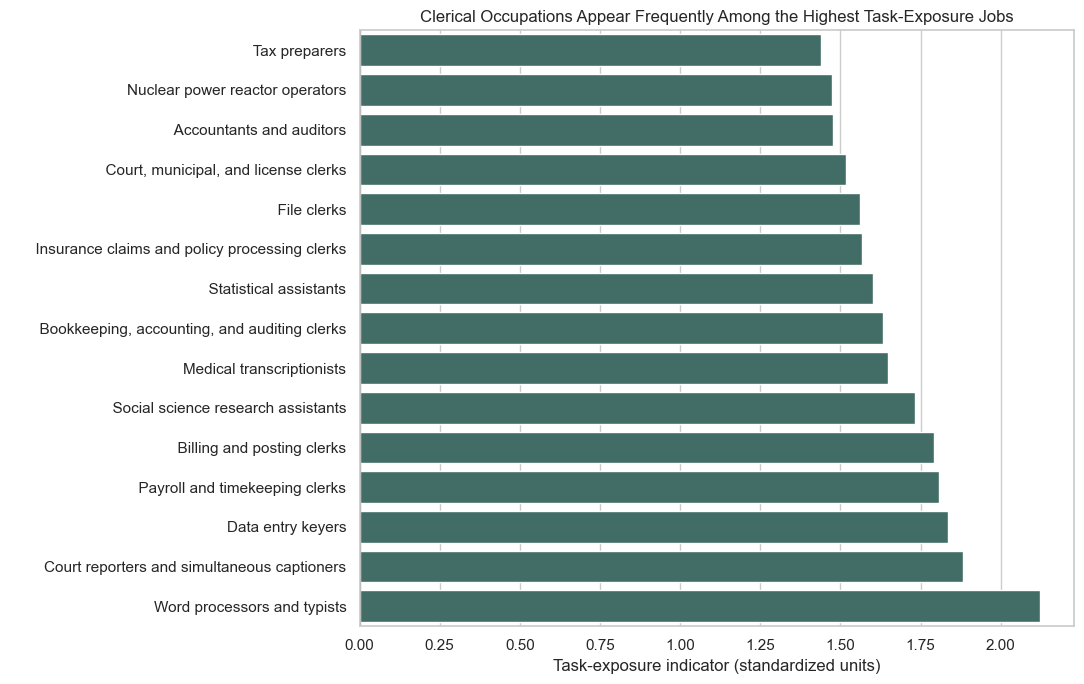

In [28]:
top_baseline = eda.nlargest(15, "Task-based exposure indicator").sort_values(
    "Task-based exposure indicator"
)
plt.figure(figsize=(11, 7))
sns.barplot(
    data=top_baseline,
    x="Task-based exposure indicator",
    y="Occupation",
    color="#3B746B",
)
plt.axvline(0, color="#555555", linewidth=0.8)
plt.title("Clerical Occupations Appear Frequently Among the Highest Task-Exposure Jobs")
plt.xlabel("Task-exposure indicator (standardized units)")
plt.ylabel("")
plt.tight_layout()
plt.show()


# Advanced Analysis: From Task Exposure to Retraining Priority


The data pipeline and exploratory results are set up in the preceding sections. This is the analytical depth that can be added to support a workforce funding recommendation. It evaluates the level of exposure across various scenarios, compares the expert-designed indicator to a data-driven structure, classifies occupations by job characteristics, develops a clear funding-priority score, and proposes transition options for exploration.

Task exposure and employment risk and retraining priority are treated separately in the analysis, on purpose. High exposure score indicates that a job has a lot of routine or information processing tasks. It does not indicate that the occupation will go away or that a worker will lose their job.


## Research design and decision question


**Decision question:** When retraining funds are limited, which occupations should a workforce board examine first?


**Analytical question:** Which occupations combine high task exposure, a large workforce, weak projected growth, and continuing annual openings?


One-six-digit SOC occupation is the unit of analysis. Task, skill, and work-context measures are provided by O\*NET; employment, 2025 projected employment, projected growth, annual openings, and median wages are provided by BLS. It is an observational, rather than causal, analysis, and it is at the occupation level, which allows for prioritization and pilot design, but not causal claims regarding automation or the loss of individual jobs.


In [34]:
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler


In [36]:
analysis_df = eda.copy()


In [38]:
analysis_audit = pd.DataFrame({
    "Check": [
        "Occupation rows",
        "Unique SOC codes",
        "Duplicate SOC codes",
        "Complete exposure scores",
        "Complete employment values",
        "Complete projection values",
    ],
    "Result": [
        len(analysis_df),
        analysis_df["SOC"].nunique(),
        analysis_df["SOC"].duplicated().sum(),
        analysis_df["Task-based exposure indicator"].notna().sum(),
        analysis_df["Employment 2025 (thousands)"].notna().sum(),
        analysis_df["Projected growth (%)"].notna().sum(),
    ]
})
display(analysis_audit)


,Check,Result
0,Occupation rows,819
1,Unique SOC codes,819
2,Duplicate SOC codes,0
3,Complete exposure scores,819
4,Complete employment values,819
5,Complete projection values,819


## 1. Construct validity: do the selected variables behave as intended?


Indicator theory-based: Routine information-processing features raise exposure; creative, judgement, interpersonal, caring, physical and communication features lower exposure. Below is the correlation heatmap to check redundancy and direction. A strong correlation does not mean that the index is invalid, but that it indicates when multiple variables are measuring the same part of the work and thus are having more influence than expected.


In [41]:
feature_labels = {
    "Processing Information": "Process info",
    "Analyzing Data or Information": "Analyze data",
    "Documenting/Recording Information": "Document info",
    "Working with Computers": "Computer work",
    "Performing Administrative Activities": "Admin work",
    "Importance of Repeating Same Tasks": "Repeat tasks",
    "Thinking Creatively": "Creativity",
    "Making Decisions and Solving Problems": "Judgment",
    "Establishing and Maintaining Interpersonal Relationships": "Relationships",
    "Assisting and Caring for Others": "Care for others",
    "Performing General Physical Activities": "Physical activity",
    "Freedom to Make Decisions": "Decision freedom",
    "Critical Thinking": "Critical thinking",
    "Active Listening": "Active listening",
    "Speaking": "Speaking",
}


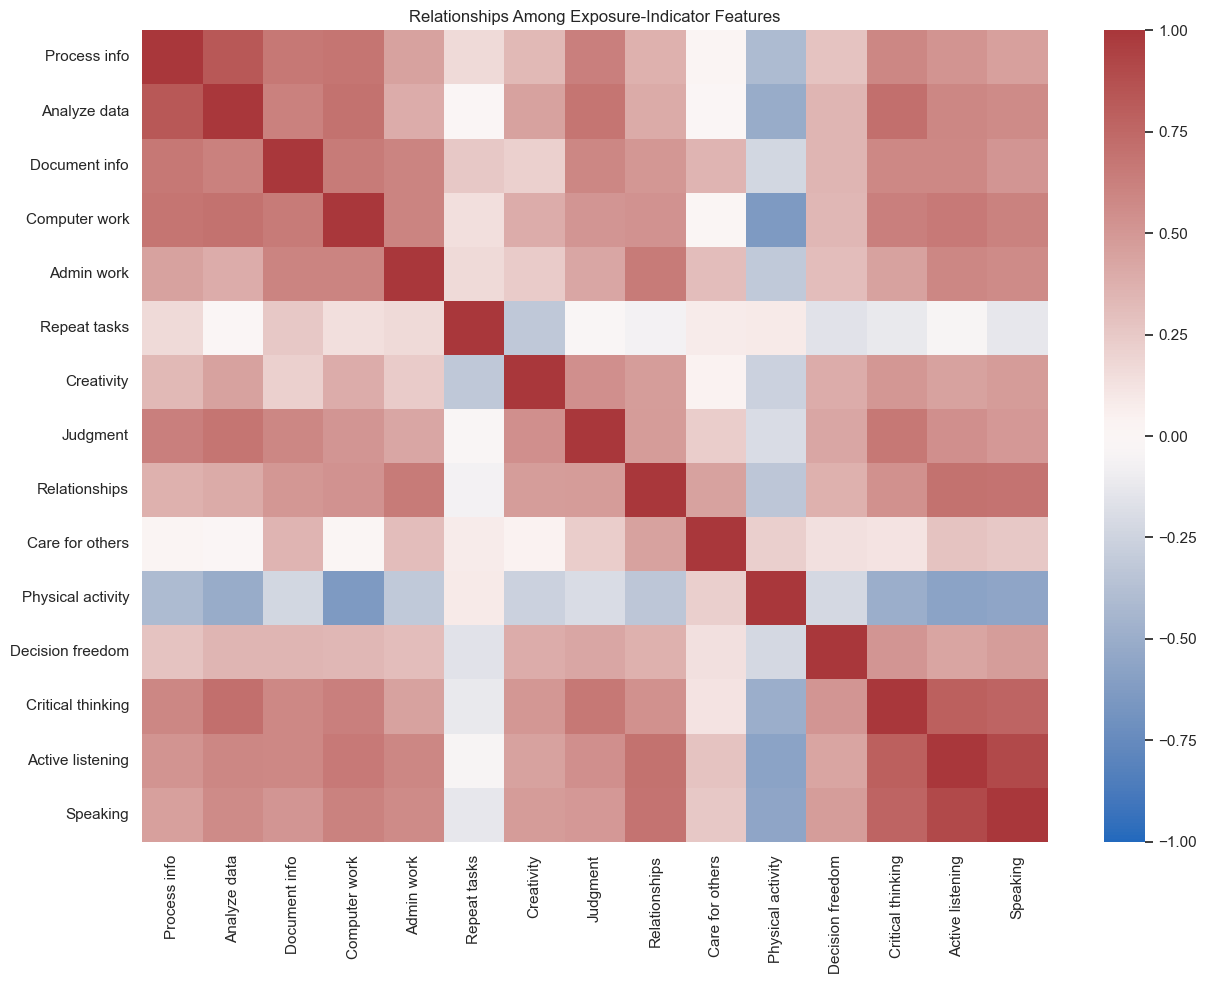

In [43]:
correlation_matrix = analysis_df[model_features].corr().rename(
    index=feature_labels, columns=feature_labels
)
plt.figure(figsize=(13, 10))
sns.heatmap(correlation_matrix, cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Relationships Among Exposure-Indicator Features")
plt.tight_layout()
plt.show()


## 2. Scenario sensitivity: would reasonable weights change the ranking?


No single weight can be prescribed for any given level of automation exposure. There are thus four possible scenarios that could be considered reasonable: balanced concept weight, more weight on digital work, more weight on administrative work, and more weight on protection. The rank correlation and Top-20 overlap will test the sensitivity to one specific subjective prescription.


In [46]:
scenario_weights = {
    "Balanced": {feature: 1.0 for feature in positive_features} |
                {feature: -1.0 for feature in protective_features},
    "Information-heavy": {
        **{feature: (2.0 if feature in [
            "Processing Information", "Analyzing Data or Information",
            "Documenting/Recording Information", "Working with Computers"
        ] else 1.0) for feature in positive_features},
        **{feature: -1.0 for feature in protective_features},
    },
    "Routine-heavy": {
        **{feature: (2.0 if feature in [
            "Performing Administrative Activities",
            "Importance of Repeating Same Tasks"
        ] else 1.0) for feature in positive_features},
        **{feature: -1.0 for feature in protective_features},
    },
    "Human-protection-heavy": {
        **{feature: 1.0 for feature in positive_features},
        **{feature: (-2.0 if feature in [
            "Thinking Creatively", "Making Decisions and Solving Problems",
            "Establishing and Maintaining Interpersonal Relationships",
            "Assisting and Caring for Others", "Critical Thinking",
            "Active Listening", "Speaking"
        ] else -1.0) for feature in protective_features},
    },
}


In [48]:
scenario_score_columns = []
for scenario, weights in scenario_weights.items():
    column = f"Exposure: {scenario}"
    numerator = sum(
        weight * analysis_df[f"z_{feature}"]
        for feature, weight in weights.items()
    )
    analysis_df[column] = numerator / sum(abs(weight) for weight in weights.values())
    scenario_score_columns.append(column)


In [50]:
scenario_rank_correlations = analysis_df[scenario_score_columns].rank(
    ascending=False
).corr(method="spearman")
display(scenario_rank_correlations.round(3))


,Exposure: Balanced,Exposure: Information-heavy,Exposure: Routine-heavy,Exposure: Human-protection-heavy
Exposure: Balanced,1.000,0.775,0.951,0.839
Exposure: Information-heavy,0.775,1.000,0.821,0.365
Exposure: Routine-heavy,0.951,0.821,1.000,0.708
Exposure: Human-protection-heavy,0.839,0.365,0.708,1.000


In [52]:
top_n = 20
balanced_top = set(analysis_df.nlargest(top_n, "Exposure: Balanced")["SOC"])
overlap_rows = []
for column in scenario_score_columns:
    scenario_top = set(analysis_df.nlargest(top_n, column)["SOC"])
    overlap_rows.append({
        "Scenario": column.replace("Exposure: ", ""),
        "Top-20 overlap with balanced": len(balanced_top & scenario_top),
        "Overlap proportion": len(balanced_top & scenario_top) / top_n,
    })
display(pd.DataFrame(overlap_rows).round(2))


,Scenario,Top-20 overlap with balanced,Overlap proportion
0,Balanced,20,1.000
1,Information-heavy,15,0.750
2,Routine-heavy,16,0.800
3,Human-protection-heavy,8,0.400


In [54]:
rank_table = analysis_df[["SOC", "Occupation"]].copy()
for column in scenario_score_columns:
    rank_table[column.replace("Exposure: ", "") + " rank"] = (
        analysis_df[column].rank(ascending=False, method="min").astype(int)
    )


In [56]:
rank_columns = [column for column in rank_table if column.endswith(" rank")]
rank_table["Best rank"] = rank_table[rank_columns].min(axis=1)
rank_table["Worst rank"] = rank_table[rank_columns].max(axis=1)
rank_table["Rank range"] = rank_table["Worst rank"] - rank_table["Best rank"]


In [58]:
focus_mask = rank_table["Occupation"].str.contains(
    "Bookkeeping|Payroll|Data Entry|Word Processors|Billing", case=False, regex=True
)
display(rank_table.loc[focus_mask].sort_values("Balanced rank").head(15))


,SOC,Occupation,Balanced rank,Information-heavy rank,Routine-heavy rank,Human-protection-heavy rank,Best rank,Worst rank,Rank range
0,43-9022,Word processors and typists,1,1,1,6,1,6,5
4,43-3021,Billing and posting clerks,3,5,4,4,3,5,2
3,43-3051,Payroll and timekeeping clerks,4,7,3,15,3,15,12
2,43-9021,Data entry keyers,5,4,5,13,4,13,9
7,43-3031,"Bookkeeping, accounting, and auditing cl...",6,14,6,10,6,14,8
28,43-4161,"Human resources assistants, except payro...",45,36,27,247,27,247,220


## 3. Monte Carlo uncertainty: how stable is each occupation's tier?


The scenario analysis involves four chosen alternatives. The simulation presented below takes it to the next level through selecting 1,000 distinct weight combinations. Weights of the positive and protective characteristics change on each iteration. The output is the uncertainty range for each profession regarding its rank and the likelihood of remaining in the high-exposure quartile. It does not capture sampling variability; rather, it captures the uncertainty from analysis weights.


In [62]:
rng = np.random.default_rng(692)
n_simulations = 1000
positive_matrix = analysis_df[positive_z_columns].to_numpy()
protective_matrix = analysis_df[protective_z_columns].to_numpy()
simulation_ranks = np.empty((len(analysis_df), n_simulations), dtype=np.int16)


In [64]:
for simulation in range(n_simulations):
    positive_weight = rng.dirichlet(np.ones(len(positive_z_columns)))
    protective_weight = rng.dirichlet(np.ones(len(protective_z_columns)))
    simulated_score = (
        positive_matrix @ positive_weight -
        protective_matrix @ protective_weight
    )
    order = np.argsort(-simulated_score)
    ranks = np.empty(len(order), dtype=np.int16)
    ranks[order] = np.arange(1, len(order) + 1)
    simulation_ranks[:, simulation] = ranks


In [66]:
analysis_df["Median simulated exposure rank"] = np.median(simulation_ranks, axis=1)
analysis_df["Exposure rank 5th percentile"] = np.percentile(simulation_ranks, 5, axis=1)
analysis_df["Exposure rank 95th percentile"] = np.percentile(simulation_ranks, 95, axis=1)
analysis_df["Probability of top exposure quartile"] = (
    simulation_ranks <= int(np.ceil(len(analysis_df) * 0.25))
).mean(axis=1)


In [68]:
uncertainty_columns = [
    "Occupation", "Task-based exposure indicator",
    "Median simulated exposure rank", "Exposure rank 5th percentile",
    "Exposure rank 95th percentile", "Probability of top exposure quartile"
]
focus_uncertainty = analysis_df.loc[
    analysis_df["Occupation"].str.contains(
        "Bookkeeping|Payroll|Data Entry|Word Processors|Billing",
        case=False, regex=True
    ), uncertainty_columns
].sort_values("Median simulated exposure rank")
display(focus_uncertainty.head(15).round(3))


,Occupation,Task-based exposure indicator,Median simulated exposure rank,Exposure rank 5th percentile,Exposure rank 95th percentile,Probability of top exposure quartile
0,Word processors and typists,2.122,2.000,1.000,18.050,1.000
2,Data entry keyers,1.835,6.000,1.000,35.050,1.000
3,Payroll and timekeeping clerks,1.808,7.000,2.000,32.050,1.000
4,Billing and posting clerks,1.790,7.000,1.950,46.000,1.000
7,"Bookkeeping, accounting, and auditing cl...",1.633,12.000,4.000,63.050,0.999
28,"Human resources assistants, except payro...",1.249,36.000,12.000,162.150,0.975


## 4. Data-driven comparison: does the feature structure support the expert index?


The Principal Component Analysis offers an unsupervised comparison in the sense that it captures the common variance of all selected occupational attributes without using the expert developed measure of exposure. Agreement of the first components with the exposure index gives us greater confidence that we have uncovered an underlying pattern in the data set. Disagreement is also interesting since it shows us that the policy index is a normative construction.

In [71]:
X = analysis_df[model_features].to_numpy()
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(random_state=692)
principal_components = pca.fit_transform(X_scaled)


In [73]:
pca_summary = pd.DataFrame({
    "Component": np.arange(1, len(model_features) + 1),
    "Explained variance": pca.explained_variance_ratio_,
    "Cumulative variance": np.cumsum(pca.explained_variance_ratio_),
})
display(pca_summary.head(8).round(3))


,Component,Explained variance,Cumulative variance
0,1,0.487,0.487
1,2,0.110,0.598
2,3,0.103,0.701
3,4,0.073,0.774
4,5,0.045,0.819
5,6,0.039,0.858
6,7,0.032,0.890
7,8,0.024,0.914


In [75]:
analysis_df["PC1"] = principal_components[:, 0]
analysis_df["PC2"] = principal_components[:, 1]
pc_correlations = pd.Series({
    "PC1": spearmanr(analysis_df["Task-based exposure indicator"], analysis_df["PC1"]).statistic,
    "PC2": spearmanr(analysis_df["Task-based exposure indicator"], analysis_df["PC2"]).statistic,
}, name="Spearman correlation with exposure indicator")
display(pc_correlations.to_frame().round(3))


,Spearman correlation with exposure indicator
PC1,-0.120
PC2,-0.312


In [77]:
loadings = pd.DataFrame(
    pca.components_[:2].T,
    index=[feature_labels.get(feature, feature) for feature in model_features],
    columns=["PC1 loading", "PC2 loading"]
)
display(loadings.reindex(loadings["PC1 loading"].abs().sort_values(ascending=False).index).round(3))


,PC1 loading,PC2 loading
Active listening,-0.325,0.021
Critical thinking,-0.318,0.142
Speaking,-0.313,0.084
Computer work,-0.304,-0.013
Analyze data,-0.300,0.100
Document info,-0.279,-0.338
Process info,-0.278,-0.063
Judgment,-0.278,-0.026
Relationships,-0.273,-0.127
Admin work,-0.256,-0.289


## 5. Occupational profiles: which jobs share similar work characteristics?


The use of clustering is for descriptive segmentation and not for predictions. Potential solutions using cluster sizes ranging from two to eight are evaluated using the silhouette score. The chosen solution will be one that is a good balance between numerical separation and interpretation by stakeholders.


In [84]:
cluster_diagnostics = []
cluster_models = {}
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=30, random_state=692)
    labels = model.fit_predict(X_scaled)
    cluster_models[k] = (model, labels)
    cluster_diagnostics.append({
        "Clusters": k,
        "Silhouette score": silhouette_score(X_scaled, labels),
        "Within-cluster variation": model.inertia_,
    })


In [86]:
cluster_diagnostics = pd.DataFrame(cluster_diagnostics)
display(cluster_diagnostics.round(3))


,Clusters,Silhouette score,Within-cluster variation
0,2,0.307,"8,026.834"
1,3,0.200,"6,892.527"
2,4,0.196,"6,250.578"
3,5,0.193,"5,839.442"
4,6,0.179,"5,487.925"
5,7,0.182,"5,226.017"
6,8,0.167,"5,027.748"


In [88]:
best_k = int(cluster_diagnostics.loc[
    cluster_diagnostics["Silhouette score"].idxmax(), "Clusters"
])
cluster_model, cluster_labels = cluster_models[best_k]
analysis_df["Cluster"] = cluster_labels + 1
print(f"Selected cluster count: {best_k}")


Selected cluster count: 2


In [90]:
cluster_profile = analysis_df.groupby("Cluster")[model_features].mean()
cluster_profile_z = pd.DataFrame(
    StandardScaler().fit_transform(cluster_profile),
    index=cluster_profile.index,
    columns=cluster_profile.columns,
)
display(cluster_profile_z.rename(columns=feature_labels).round(2))


,Process info,Analyze data,Document info,Computer work,Admin work,Repeat tasks,Creativity,Judgment,Relationships,Care for others,Physical activity,Decision freedom,Critical thinking,Active listening,Speaking
Cluster,,,,,,,,,,,,,,,
1,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,-1.000,1.000,1.000,1.000,1.000
2,-1.000,-1.000,-1.000,-1.000,-1.000,-1.000,-1.000,-1.000,-1.000,-1.000,1.000,-1.000,-1.000,-1.000,-1.000


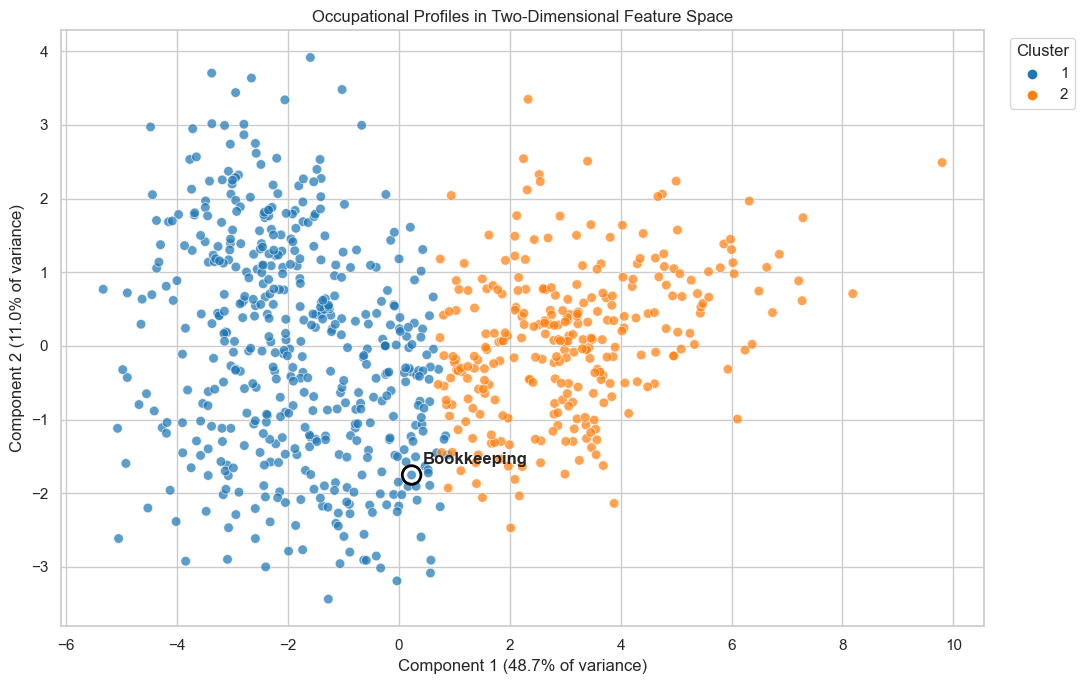

In [92]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=analysis_df, x="PC1", y="PC2", hue="Cluster",
    palette="tab10", alpha=0.72, s=48
)
bookkeeping_mask = analysis_df["Occupation"].str.contains(
    "Bookkeeping, accounting, and auditing clerks", case=False, regex=False
)
for _, row in analysis_df.loc[bookkeeping_mask].iterrows():
    plt.scatter(row["PC1"], row["PC2"], s=180, facecolors="none",
                edgecolors="black", linewidths=2)
    plt.annotate("Bookkeeping", (row["PC1"], row["PC2"]),
                 xytext=(8, 8), textcoords="offset points", fontweight="bold")
plt.title("Occupational Profiles in Two-Dimensional Feature Space")
plt.xlabel(f"Component 1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"Component 2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 6. From exposure to action: a transparent retraining-priority score


Exposure does not define the budgeting criteria alone. Below is the formula for scoring policies based on four dimensions: task exposure (40 percent), labor force size (30 percent), number of job openings per year (20 percent), and predicted decline (10 percent). Logarithm of employment and job openings is taken before percentile ranking to prevent few very large occupations from dominating. The weights used above are policy assumptions, not factual information.


In [96]:
def percentile(series):
    return series.rank(pct=True, method="average")


In [98]:
analysis_df["Exposure percentile"] = percentile(
    analysis_df["Task-based exposure indicator"]
)
analysis_df["Workforce-size percentile"] = percentile(
    np.log1p(analysis_df["Employment 2025 (thousands)"].clip(lower=0))
)
analysis_df["Openings percentile"] = percentile(
    np.log1p(analysis_df["Annual openings (thousands)"].clip(lower=0))
)
analysis_df["Decline-risk percentile"] = percentile(
    (-analysis_df["Projected growth (%)"]).clip(lower=0)
)


In [100]:
priority_components = {
    "Exposure percentile": 0.40,
    "Workforce-size percentile": 0.30,
    "Openings percentile": 0.20,
    "Decline-risk percentile": 0.10,
}
analysis_df["Retraining priority score"] = 100 * sum(
    weight * analysis_df[column]
    for column, weight in priority_components.items()
)
analysis_df["Priority rank"] = analysis_df["Retraining priority score"].rank(
    ascending=False, method="min"
).astype(int)


In [102]:
priority_columns = [
    "Priority rank", "SOC", "Occupation", "Retraining priority score",
    "Task-based exposure indicator", "Employment 2025 (thousands)",
    "Projected growth (%)", "Annual openings (thousands)",
    "Median annual wage ($)"
]
display(analysis_df.nsmallest(20, "Priority rank")[priority_columns].round(2))


,Priority rank,SOC,Occupation,Retraining priority score,Task-based exposure indicator,Employment 2025 (thousands),Projected growth (%),Annual openings (thousands),Median annual wage ($)
17,1,43-4051,Customer service representatives,97.460,1.410,"2,666.000",-5.300,289.500,"44,770.000"
7,2,43-3031,"Bookkeeping, accounting, and auditing cl...",97.350,1.630,"1,532.400",-5.600,144.100,"50,670.000"
31,3,43-9061,"Office clerks, general",96.920,1.210,"2,600.000",-6.000,249.000,"45,010.000"
71,4,43-6014,Secretaries and administrative assistant...,94.650,0.820,"1,889.800",-6.000,163.900,"47,540.000"
12,5,13-2011,Accountants and auditors,91.810,1.480,"1,595.200",5.000,115.300,"83,680.000"
4,6,43-3021,Billing and posting clerks,91.250,1.790,418.000,-0.100,37.000,"48,500.000"
101,7,43-5071,"Shipping, receiving, and inventory clerks",91.010,0.650,827.700,-7.600,61.300,"45,260.000"
16,8,23-2011,Paralegals and legal assistants,90.850,1.420,404.900,-0.300,40.800,"62,890.000"
52,9,43-3071,Tellers,89.880,0.960,339.200,-13.200,26.800,"43,030.000"
37,10,31-9092,Medical assistants,89.440,1.140,833.900,12.900,109.700,"45,690.000"


In [104]:
bookkeeping = analysis_df.loc[
    analysis_df["Occupation"].str.contains(
        "Bookkeeping, accounting, and auditing clerks", case=False, regex=False
    ), priority_columns + [
        "Exposure percentile", "Workforce-size percentile",
        "Openings percentile", "Decline-risk percentile",
        "Probability of top exposure quartile"
    ]
]
display(bookkeeping.round(3))


,Priority rank,SOC,Occupation,Retraining priority score,Task-based exposure indicator,Employment 2025 (thousands),Projected growth (%),Annual openings (thousands),Median annual wage ($),Exposure percentile,Workforce-size percentile,Openings percentile,Decline-risk percentile,Probability of top exposure quartile
7,2,43-3031,"Bookkeeping, accounting, and auditing cl...",97.350,1.633,"1,532.400",-5.600,144.100,"50,670.000",0.991,0.980,0.974,0.879,0.999


## 7. Priority sensitivity: does bookkeeping remain important under other policies?


Boards could prioritize the four dimensions differently from each other. The table below shows how an exposure-based approach, a worker-based approach, an openings-based approach, and the balanced approach can be compared. Recommendation will become more convincing if the profession keeps its high position according to several reasonable approaches instead of just one favorite one.


In [107]:
priority_policies = {
    "Proposed": [0.40, 0.30, 0.20, 0.10],
    "Exposure-first": [0.60, 0.20, 0.10, 0.10],
    "Worker-scale": [0.25, 0.50, 0.15, 0.10],
    "Openings-focused": [0.25, 0.20, 0.45, 0.10],
    "Equal weights": [0.25, 0.25, 0.25, 0.25],
}
component_columns = list(priority_components)
policy_rank_columns = []
for policy, weights in priority_policies.items():
    score_column = f"Priority score: {policy}"
    rank_column = f"Priority rank: {policy}"
    analysis_df[score_column] = 100 * sum(
        weight * analysis_df[column]
        for column, weight in zip(component_columns, weights)
    )
    analysis_df[rank_column] = analysis_df[score_column].rank(
        ascending=False, method="min"
    ).astype(int)
    policy_rank_columns.append(rank_column)


In [109]:
analysis_df["Best policy rank"] = analysis_df[policy_rank_columns].min(axis=1)
analysis_df["Worst policy rank"] = analysis_df[policy_rank_columns].max(axis=1)
analysis_df["Median policy rank"] = analysis_df[policy_rank_columns].median(axis=1)


In [111]:
policy_focus = analysis_df.loc[
    analysis_df["Occupation"].str.contains(
        "Bookkeeping|Payroll|Data Entry|Word Processors|Billing",
        case=False, regex=True
    ), ["SOC", "Occupation"] + policy_rank_columns + [
        "Best policy rank", "Worst policy rank", "Median policy rank"
    ]
].sort_values("Median policy rank")
display(policy_focus.head(15))


,SOC,Occupation,Priority rank: Proposed,Priority rank: Exposure-first,Priority rank: Worker-scale,Priority rank: Openings-focused,Priority rank: Equal weights,Best policy rank,Worst policy rank,Median policy rank
7,43-3031,"Bookkeeping, accounting, and auditing cl...",2,1,3,3,3,1,3,3.000
4,43-3021,Billing and posting clerks,6,4,8,10,10,4,10,8.000
3,43-3051,Payroll and timekeeping clerks,18,9,37,47,13,9,47,18.000
2,43-9021,Data entry keyers,30,13,59,76,20,13,76,30.000
28,43-4161,"Human resources assistants, except payro...",52,25,106,105,30,25,106,52.000
0,43-9022,Word processors and typists,130,42,253,307,112,42,307,130.000


In [113]:
quadrant = analysis_df.copy()
x_cut = quadrant["Task-based exposure indicator"].median()
y_cut = quadrant["Employment 2025 (thousands)"].median()


Text(0.5, 1.0, 'Highest Review Priority Combines High Exposure and Large Workforce Size')

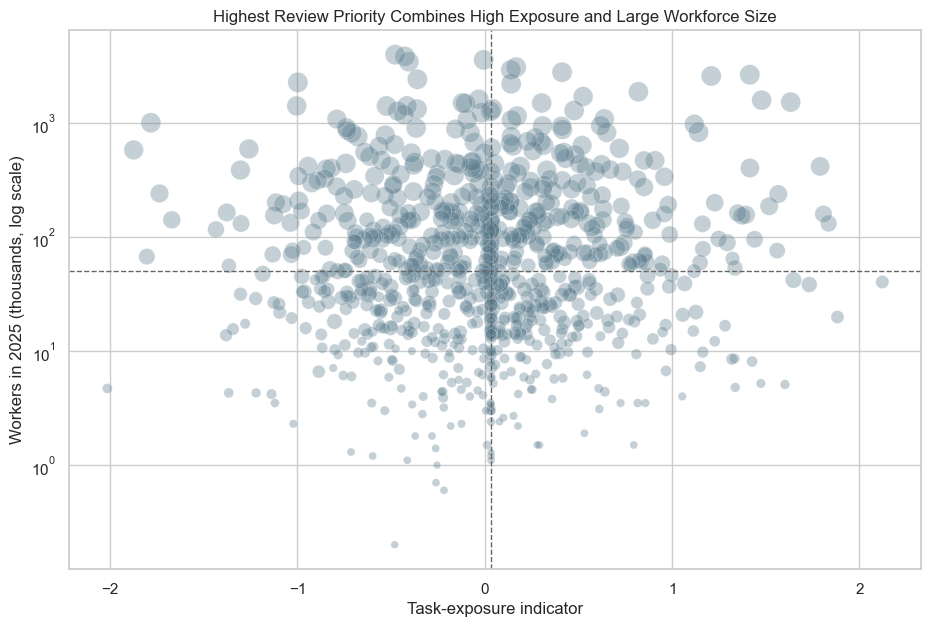

In [115]:
plt.figure(figsize=(11, 7))
sizes = 30 + 180 * percentile(quadrant["Annual openings (thousands)"])
plt.scatter(
    quadrant["Task-based exposure indicator"],
    quadrant["Employment 2025 (thousands)"],
    s=sizes, alpha=0.35, color="#587A8C", edgecolor="white", linewidth=0.4
)
plt.axvline(x_cut, color="#666666", linestyle="--", linewidth=1)
plt.axhline(y_cut, color="#666666", linestyle="--", linewidth=1)
plt.yscale("log")
plt.xlabel("Task-exposure indicator")
plt.ylabel("Workers in 2025 (thousands, log scale)")
plt.title("Highest Review Priority Combines High Exposure and Large Workforce Size")


## 8. Exploratory career transitions for bookkeeping workers


The transition analysis involves the comparison between the O*NET characteristics profile of bookkeepers and occupations with lower exposure and positive growth projections. Occupations with similar work characteristics can be identified by cosine similarity. The occupations identified here are merely potential candidates and further considerations like education, license requirements, job demand, and worker preference need to be considered.


In [122]:
bookkeeping_indices = analysis_df.index[
    analysis_df["Occupation"].str.contains(
        "Bookkeeping, accounting, and auditing clerks", case=False, regex=False
    )
].tolist()


In [124]:
if bookkeeping_indices:
    bookkeeping_index = bookkeeping_indices[0]
    similarities = cosine_similarity(
        X_scaled[bookkeeping_index].reshape(1, -1), X_scaled
    ).ravel()
    analysis_df["Similarity to bookkeeping"] = similarities
    candidate_transitions = analysis_df.loc[
        (analysis_df.index != bookkeeping_index) &
        (analysis_df["Task-based exposure indicator"] <
         analysis_df.loc[bookkeeping_index, "Task-based exposure indicator"]) &
        (analysis_df["Projected growth (%)"] >= 0)
    ].nlargest(12, "Similarity to bookkeeping")[[
        "SOC", "Occupation", "Similarity to bookkeeping",
        "Task-based exposure indicator", "Projected growth (%)",
        "Annual openings (thousands)", "Median annual wage ($)"
    ]]
    display(candidate_transitions.round(3))
else:
    print("Bookkeeping occupation was not found; transition analysis was skipped.")


,SOC,Occupation,Similarity to bookkeeping,Task-based exposure indicator,Projected growth (%),Annual openings (thousands),Median annual wage ($)
30,29-2072,Medical records specialists,0.885,1.228,7.800,14.000,"51,140.000"
11,43-4031,"Court, municipal, and license clerks",0.787,1.518,3.400,17.100,"48,700.000"
14,13-2082,Tax preparers,0.770,1.440,4.700,9.400,"54,920.000"
12,13-2011,Accountants and auditors,0.747,1.478,5.000,115.300,"83,680.000"
43,19-4013,Food science technicians,0.715,1.057,4.800,3.000,"52,130.000"
36,23-2093,"Title examiners, abstractors, and sear...",0.631,1.149,2.100,5.300,"58,650.000"
121,43-4181,Reservation and transportation ticket ag...,0.617,0.574,2.500,11.800,"44,390.000"
26,19-4099,"Life, physical, and social science tec...",0.606,1.295,4.400,11.200,"62,280.000"
20,43-4061,"Eligibility interviewers, government pro...",0.591,1.350,1.600,12.700,"54,210.000"
239,41-3021,Insurance sales agents,0.576,0.257,3.300,43.100,"62,280.000"


## 9. Claims audit and decision boundary


The following table identifies those claims that have been substantiated through this analysis and those claims that need further substantiation through additional research to avoid overstatement of this study’s findings.

In [131]:
claims_audit = pd.DataFrame({
    "Claim": [
        "Some occupations contain more exposed task characteristics than others.",
        "Bookkeeping affects enough workers and openings to merit pilot consideration.",
        "Automation caused projected employment declines.",
        "A specific bookkeeping worker will lose a job.",
        "The proposed training improves employment or wages.",
    ],
    "Supported now?": ["Yes", "Yes, for prioritization", "No", "No", "Not yet"],
    "Evidence needed or caution": [
        "O*NET feature comparison and sensitivity analysis",
        "Exposure, employment, openings, projections, and policy-weight sensitivity",
        "Causal or longitudinal evidence isolating automation",
        "Individual-level longitudinal worker data",
        "Pilot with pre-specified outcomes and a credible comparison group",
    ],
})
display(claims_audit)


,Claim,Supported now?,Evidence needed or caution
0,Some occupations contain more exposed task cha...,Yes,O*NET feature comparison and sensitivity analysis
1,Bookkeeping affects enough workers and opening...,"Yes, for prioritization","Exposure, employment, openings, projections, a..."
2,Automation caused projected employment declines.,No,Causal or longitudinal evidence isolating auto...
3,A specific bookkeeping worker will lose a job.,No,Individual-level longitudinal worker data
4,The proposed training improves employment or w...,Not yet,Pilot with pre-specified outcomes and a credib...


  
## 10. Pilot evaluation plan


The analytical recommendation is to **test**, rather than scale, an upskilling initiative for bookkeepers. A reasonable pilot project will define eligibility criteria, course content, period for follow-up, and desired outcomes prior to recruitment. Some relevant outcomes are whether individuals complete the course, obtain credentials, retain employment, move into a less repetitive job, experience a wage change, and time to re-employment. Ideally, if feasible, participants would be randomly selected from among eligible workers; otherwise, matching or phasing in could help mitigate selection effects.


In [135]:
pilot_measurement_plan = pd.DataFrame({
    "Stage": ["Select", "Train", "Measure", "Decide"],
    "Required record": [
        "Eligibility, baseline job, wage, tenure, demographics, consent",
        "Attendance, completion, credential, training dosage",
        "Employment status, role transition, wage, time to reemployment",
        "Effect estimate, cost per successful outcome, subgroup equity checks",
    ],
    "Timing": ["Before training", "During training", "3, 6, and 12 months", "After follow-up"],
})
display(pilot_measurement_plan)


,Stage,Required record,Timing
0,Select,"Eligibility, baseline job, wage, tenure, demog...",Before training
1,Train,"Attendance, completion, credential, training d...",During training
2,Measure,"Employment status, role transition, wage, time...","3, 6, and 12 months"
3,Decide,"Effect estimate, cost per successful outcome, ...",After follow-up


## Supplemental supervised analysis: projected occupational growth


The primary analysis is a decision-prioritization study, rather than a layoffs prediction model. The secondary analysis tests whether the O\*NET work attributes have out-of-sample information on BLS projected growth. This study examines prediction only and not whether automation is the reason for employment change.

### Modeling protocol


The mean prediction serves as the baseline. The stable relationship is checked by using a regularized linear regression model while the nonlinearity and interaction effects are tested by using a random forest regression model. Five-fold cross-validation is done repeatedly using the same resampled data in both the models.


In [140]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RepeatedKFold, KFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline


In [142]:
supervised_data = analysis_df.dropna(subset=["Projected growth (%)"]).copy()
X_supervised = supervised_data[model_features]
y_supervised = supervised_data["Projected growth (%)"]


In [144]:
print("Occupations used:", len(supervised_data))
display(y_supervised.describe().to_frame("Projected growth (%)").round(2))


Occupations used: 819


,Projected growth (%)
count,819.000
mean,2.030
std,7.240
min,-34.400
25%,-0.400
50%,2.700
75%,5.500
max,41.000


In [146]:
candidate_models = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Regularized linear": Pipeline([
        ("scale", StandardScaler()),
        ("model", Ridge(alpha=10.0)),
    ]),
    "Random forest": RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=5,
        max_features="sqrt",
        random_state=692,
        n_jobs=-1,
    ),
}


In [148]:
repeated_cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=692)
model_scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}


In [150]:
model_results = []
for model_name, model in candidate_models.items():
    scores = cross_validate(
        model, X_supervised, y_supervised,
        cv=repeated_cv, scoring=model_scoring, n_jobs=-1,
    )
    model_results.append({
        "Model": model_name,
        "Mean MAE": -scores["test_MAE"].mean(),
        "SD MAE": scores["test_MAE"].std(),
        "Mean RMSE": -scores["test_RMSE"].mean(),
        "Mean R-squared": scores["test_R2"].mean(),
    })


In [152]:
model_results = pd.DataFrame(model_results).sort_values("Mean MAE")
display(model_results.round(3))


,Model,Mean MAE,SD MAE,Mean RMSE,Mean R-squared
2,Random forest,4.408,0.341,6.371,0.215
1,Regularized linear,4.642,0.339,6.496,0.183
0,Mean baseline,4.884,0.374,7.219,-0.006


### Out-of-fold diagnostic


Every diagnostic prediction below is generated by a model that did not train on that occupation. This avoids the misleading optimism of plotting fitted values from the complete data.


In [156]:
diagnostic_cv = KFold(n_splits=5, shuffle=True, random_state=692)
best_model_name = model_results.loc[
    model_results["Model"] != "Mean baseline", "Model"
].iloc[0]
best_model = candidate_models[best_model_name]


In [158]:
out_of_fold_prediction = cross_val_predict(
    best_model, X_supervised, y_supervised,
    cv=diagnostic_cv, n_jobs=-1,
)
supervised_data["Out-of-fold prediction"] = out_of_fold_prediction
supervised_data["Residual"] = y_supervised - out_of_fold_prediction


In [160]:
oof_metrics = pd.Series({
    "MAE": mean_absolute_error(y_supervised, out_of_fold_prediction),
    "RMSE": mean_squared_error(y_supervised, out_of_fold_prediction) ** 0.5,
    "R-squared": r2_score(y_supervised, out_of_fold_prediction),
}, name=best_model_name)
display(oof_metrics.to_frame("Out-of-fold result").round(3))


,Out-of-fold result
MAE,4.382
RMSE,6.375
R-squared,0.224


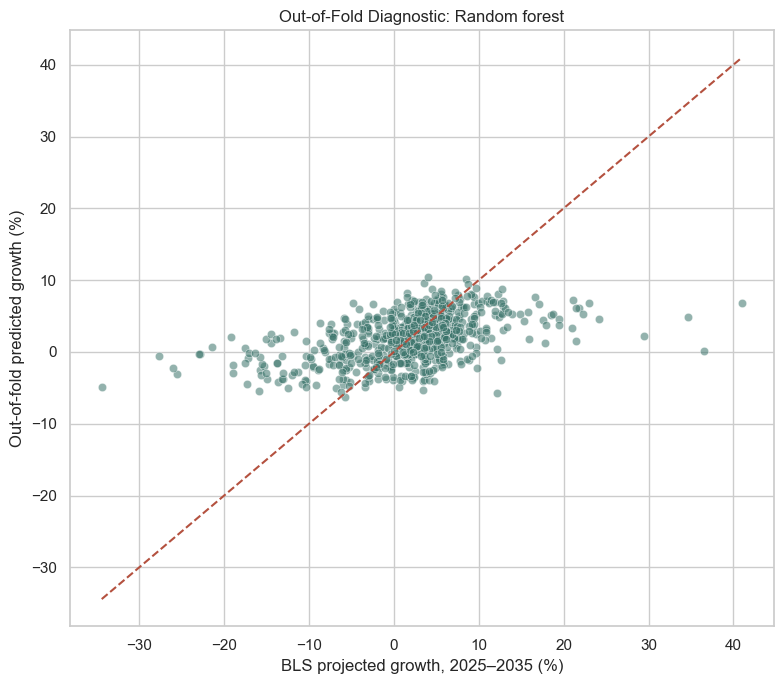

In [162]:
plt.figure(figsize=(8, 7))
sns.scatterplot(
    data=supervised_data,
    x="Projected growth (%)",
    y="Out-of-fold prediction",
    alpha=0.55,
    color="#3B746B",
)
plot_min = min(y_supervised.min(), out_of_fold_prediction.min())
plot_max = max(y_supervised.max(), out_of_fold_prediction.max())
plt.plot([plot_min, plot_max], [plot_min, plot_max], "--", color="#B4513F")
plt.xlabel("BLS projected growth, 2025–2035 (%)")
plt.ylabel("Out-of-fold predicted growth (%)")
plt.title(f"Out-of-Fold Diagnostic: {best_model_name}")
plt.tight_layout()
plt.show()


### Error analysis by occupational group


Group-level errors show where the selected model is less reliable. The model should not be interpreted confidently for groups with relatively high error even when its overall metric appears reasonable.


In [166]:
supervised_data["Absolute error"] = supervised_data["Residual"].abs()
group_error = (
    supervised_data.groupby("Major group")
    .agg(
        Occupations=("SOC", "count"),
        Mean_absolute_error=("Absolute error", "mean"),
        Median_absolute_error=("Absolute error", "median"),
        Mean_residual=("Residual", "mean"),
    )
    .sort_values("Mean_absolute_error", ascending=False)
)
display(group_error.round(2))


,Occupations,Mean_absolute_error,Median_absolute_error,Mean_residual
Major group,,,,
Office and administrative support,54,6.490,4.010,-4.840
Computer and mathematical,21,6.400,3.870,3.150
Production,103,6.250,5.500,-3.430
"Installation, maintenance, and repair",51,5.450,3.390,2.000
Healthcare support,16,5.420,3.690,3.800
Business and financial,30,4.860,3.910,0.900
Construction and extraction,59,4.680,3.110,0.870
Healthcare practitioners,70,4.440,2.930,2.190
Food preparation and serving,17,4.440,3.930,3.880


### Permutation importance


Permutation importance measures how much predictive error increases after one feature is shuffled. It shows model reliance, not causal influence. Correlated O\*NET variables may share or mask importance.


In [170]:
best_model.fit(X_supervised, y_supervised)
importance = permutation_importance(
    best_model, X_supervised, y_supervised,
    scoring="neg_mean_absolute_error",
    n_repeats=25,
    random_state=692,
    n_jobs=-1,
)
importance_table = pd.DataFrame({
    "Feature": model_features,
    "Mean importance": importance.importances_mean,
    "SD importance": importance.importances_std,
}).sort_values("Mean importance", ascending=False)
display(importance_table.round(3))


,Feature,Mean importance,SD importance
12,Critical Thinking,0.536,0.040
9,Assisting and Caring for Others,0.393,0.031
10,Performing General Physical Activities,0.330,0.022
7,Making Decisions and Solving Problems,0.309,0.016
2,Documenting/Recording Information,0.278,0.022
11,Freedom to Make Decisions,0.251,0.017
1,Analyzing Data or Information,0.243,0.014
3,Working with Computers,0.243,0.015
14,Speaking,0.235,0.017
13,Active Listening,0.220,0.015


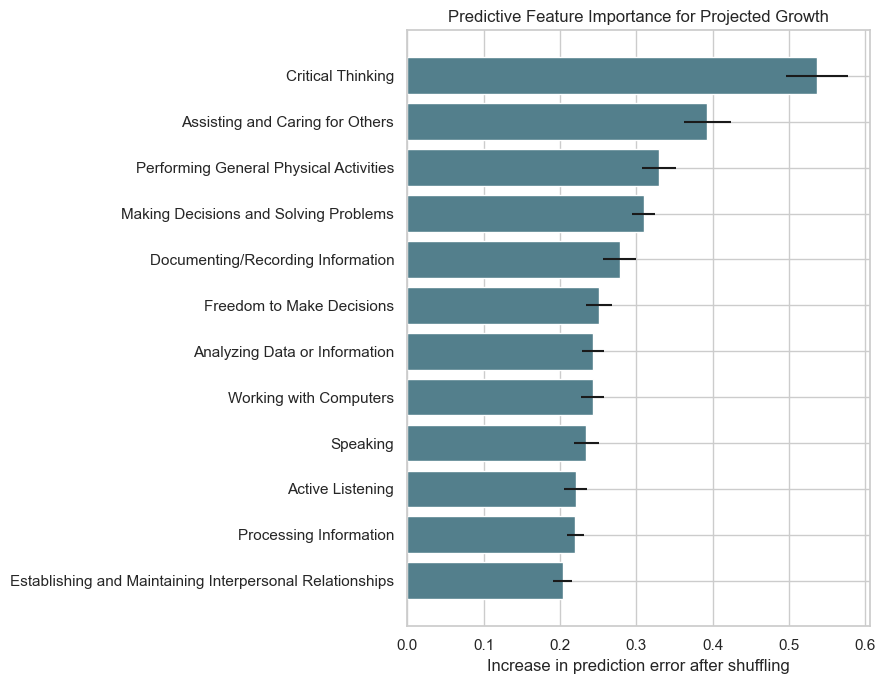

In [172]:
plt.figure(figsize=(9, 7))
plot_importance = importance_table.head(12).sort_values("Mean importance")
plt.barh(
    plot_importance["Feature"],
    plot_importance["Mean importance"],
    xerr=plot_importance["SD importance"],
    color="#537F8C",
)
plt.xlabel("Increase in prediction error after shuffling")
plt.ylabel("")
plt.title("Predictive Feature Importance for Projected Growth")
plt.tight_layout()
plt.show()


### Supervised-analysis conclusion


Supplemental models will be effective only when they perform much better than the mean model. Even if the model performs better, it cannot be considered as a substitute for the transparent policy score. Poor performance will be an important finding since occupation task attributes do not fully explain the job growth forecast.


## Ethics and external validity


It is not possible to know all the discrepancies that might be present at the level of region, company and employee. This data needs to be verified locally and reviewed by people. The score should never be applied to identify an employee as replaceable or lay him/her off.


In [176]:
governance_checklist = pd.DataFrame({
    "Review area": [
        "Local validity", "Worker impact", "Equity", "Transparency",
        "Data freshness", "Human review", "Outcome evaluation"
    ],
    "Required check": [
        "Confirm employment, openings, and employers in the service region",
        "Describe task change without labeling workers as replaceable",
        "Audit access and outcomes across demographic groups",
        "Publish variables, weights, exclusions, and sensitivity results",
        "Refresh O*NET and BLS inputs on a defined schedule",
        "Require staff review before funding decisions",
        "Use a comparison strategy and pre-specified pilot outcomes",
    ],
})
display(governance_checklist)


,Review area,Required check
0,Local validity,"Confirm employment, openings, and employers in..."
1,Worker impact,Describe task change without labeling workers ...
2,Equity,Audit access and outcomes across demographic g...
3,Transparency,"Publish variables, weights, exclusions, and se..."
4,Data freshness,Refresh O*NET and BLS inputs on a defined sche...
5,Human review,Require staff review before funding decisions
6,Outcome evaluation,Use a comparison strategy and pre-specified pi...


## Reproducibility record


The final report includes the data input, dimensions, number of duplicates, random seed number, and version of R packages used. The random seed number 692 is fixed for all simulations and algorithms.


In [180]:
import platform
import sklearn
import scipy


In [182]:
reproducibility_record = pd.Series({
    "Input file": str(analysis_file),
    "Rows": len(analysis_df),
    "Columns": analysis_df.shape[1],
    "Duplicate SOC codes": analysis_df["SOC"].duplicated().sum(),
    "Random seed": 692,
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "scikit-learn": sklearn.__version__,
    "SciPy": scipy.__version__,
})
display(reproducibility_record.to_frame("Value"))


,Value
Input file,C:\Users\SAI29\eda_merged_occupations.csv
Rows,819
Columns,72
Duplicate SOC codes,0
Random seed,692
Python,3.11.5
pandas,2.0.3
NumPy,1.24.3
scikit-learn,1.3.0
SciPy,1.11.4


## Final analytical conclusion


This notebook can be used for a conclusion on screening and prioritization. Jobs that involve clerical work tend to be common among those with high exposure tasks, but mere exposure should not form the basis of funding. More robust decisions take into account factors like exposure, workforce sizes, yearly opportunities, and future projections, and then see if they hold up when tested under plausible weight changes. Bookkeeping is suitable for the pilot if it passes these tests and there is evidence of demand from workforce statistics in the locality.


In [186]:
output_directory = Path.cwd() / "advanced_outputs"
output_directory.mkdir(exist_ok=True)


In [188]:
analysis_df.to_csv(output_directory / "occupation_priority_analysis.csv", index=False)
rank_table.to_csv(output_directory / "exposure_scenario_ranks.csv", index=False)
cluster_diagnostics.to_csv(output_directory / "cluster_diagnostics.csv", index=False)
claims_audit.to_csv(output_directory / "claims_audit.csv", index=False)
pilot_measurement_plan.to_csv(output_directory / "pilot_measurement_plan.csv", index=False)
if "candidate_transitions" in globals():
    candidate_transitions.to_csv(
        output_directory / "bookkeeping_transition_candidates.csv", index=False
    )


In [190]:
print("Saved decision-ready outputs to:", output_directory.resolve())


Saved decision-ready outputs to: C:\Users\SAI29\Downloads\advanced_outputs
